<a href="https://colab.research.google.com/github/Gayathri-B-Nair/Machine_Learning_Lab/blob/main/Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

print("Loading MNIST dataset......")
X, y = fetch_openml('mnist_784', version=1, return_X_y=True,
                    as_frame=False)

print("Dataset shape:", X.shape)


Loading MNIST dataset......
Dataset shape: (70000, 784)


In [3]:

X = X[:10000].astype('float32') / 255.0
y = y[:10000].astype(int)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(Xtr))
print("Test samples:", len(Xte))


Training samples: 8000
Test samples: 2000


In [4]:

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

def relu(x):
    return np.maximum(0, x)

def tanh(x):
    return np.tanh(x)

acts = {
    'Sigmoid': (sigmoid, lambda z: sigmoid(z)*(1-sigmoid(z))),
    'ReLU': (relu, lambda z: (z > 0).astype(float)),
    'Tanh': (tanh, lambda z: 1-np.tanh(z)**2)
}


In [5]:

def train_network(name, epochs=10, batch_size=128):
    np.random.seed(42)
    act, deriv = acts[name]

    W1 = np.random.randn(784, 64) * np.sqrt(2/784)
    b1 = np.zeros((1, 64))
    W2 = np.random.randn(64, 10) * np.sqrt(1/64)
    b2 = np.zeros((1, 10))
    losses, start = [], time.time()

    for ep in range(epochs):
        order = np.random.permutation(len(Xtr))
        total = 0

        for i in range(0, len(Xtr), batch_size):
            idx = order[i:i+batch_size]
            xb, yb = Xtr[idx], ytr[idx]

            z1 = xb @ W1 + b1
            a1 = act(z1)
            z2 = a1 @ W2 + b2
            p = np.exp(z2-z2.max(axis=1, keepdims=True))
            p /= p.sum(axis=1, keepdims=True)

            total += -np.log(
                p[np.arange(len(yb)), yb] + 1e-12
            ).sum()

            dz2 = p.copy()
            dz2[np.arange(len(yb)), yb] -= 1
            dz2 /= len(yb)

            dW2, db2 = a1.T @ dz2, dz2.sum(axis=0, keepdims=True)
            dz1 = (dz2 @ W2.T) * deriv(z1)
            dW1, db1 = xb.T @ dz1, dz1.sum(axis=0, keepdims=True)

            W1 -= 0.1*dW1
            b1 -= 0.1*db1
            W2 -= 0.1*dW2
            b2 -= 0.1*db2

        loss = total / len(Xtr)
        losses.append(loss)
        print(f"{name} - Epoch {ep+1}: Loss = {loss:.4f}")

    a1 = act(Xte @ W1 + b1)
    pred = np.argmax(a1 @ W2 + b2, axis=1)
    acc = accuracy_score(yte, pred)
    elapsed = time.time() - start

    print(f"\n{name} Training Time: {elapsed:.2f} seconds")
    print(f"{name} Accuracy: {acc*100:.2f}%")
    print(classification_report(yte, pred, zero_division=0))

    return losses, elapsed, acc


In [6]:

results = {name: train_network(name) for name in acts}

df = pd.DataFrame({
    'Activation': list(results),
    'Training Time (s)': [results[n][1] for n in acts],
    'Accuracy (%)': [results[n][2]*100 for n in acts]
})

print("\nComparison Results:")
print(df.round(2).to_string(index=False))


Sigmoid - Epoch 1: Loss = 2.0911
Sigmoid - Epoch 2: Loss = 1.6356
Sigmoid - Epoch 3: Loss = 1.2376
Sigmoid - Epoch 4: Loss = 0.9745
Sigmoid - Epoch 5: Loss = 0.8099
Sigmoid - Epoch 6: Loss = 0.7017
Sigmoid - Epoch 7: Loss = 0.6255
Sigmoid - Epoch 8: Loss = 0.5698
Sigmoid - Epoch 9: Loss = 0.5277
Sigmoid - Epoch 10: Loss = 0.4940

Sigmoid Training Time: 8.05 seconds
Sigmoid Accuracy: 88.60%
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       200
           1       0.91      0.96      0.94       225
           2       0.88      0.79      0.84       198
           3       0.86      0.84      0.85       206
           4       0.92      0.90      0.91       196
           5       0.85      0.83      0.84       173
           6       0.88      0.93      0.91       203
           7       0.91      0.91      0.91       214
           8       0.88      0.83      0.85       189
           9       0.83      0.88      0.86       196

    accurac

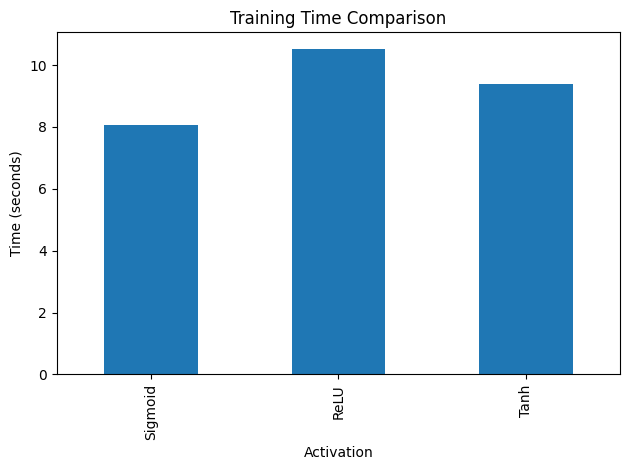

In [7]:

df.plot(x='Activation', y='Training Time (s)', kind='bar',
        legend=False, title='Training Time Comparison')
plt.ylabel('Time (seconds)')
plt.tight_layout()
plt.show()


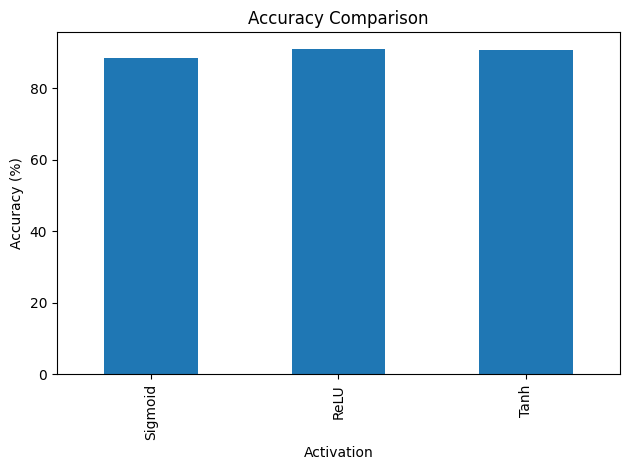

In [8]:

df.plot(x='Activation', y='Accuracy (%)', kind='bar',
        legend=False, title='Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.tight_layout()
plt.show()


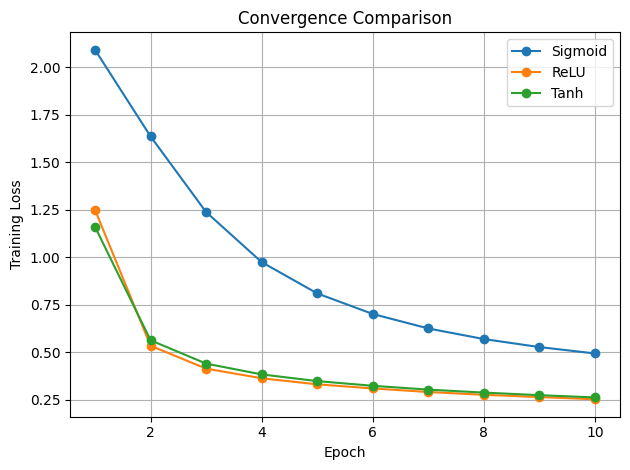

In [9]:

for name in acts:
    plt.plot(range(1, 11), results[name][0],
             marker='o', label=name)

plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Convergence Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
